# Display a multiplexed OME-TIFF image

This tutorial walks through the `OpenOME` reader of `cosmix.bioformats`:

1. open a slide and inspect its metadata,
2. navigate the resolution pyramid,
3. display single channels and color blends,
4. read regions at different levels,
5. check how the reader handles invalid inputs.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import ImageColor

from cosmix.bioformats.draw import blend_colors
from cosmix.bioformats.reader import get_slide_reader

## 1. Open the slide and inspect its metadata

In [2]:
SLIDE_PATH = "/cluster/CBIO/data1/mblons/orion/data/ORION/CRC_WSI/mIF/CRC40/P37_S83_Full_A24_C59qX_E15_20220304_200429_490805-zlib.ome.tiff"

slide = get_slide_reader(SLIDE_PATH)
print(slide)

OpenOME(name='P37_S83_Full_A24_C59qX_E15_20220304_200429_490805-zlib', dimensions=(71344, 49495), channels=19, levels=8, mpp=0.325)


In [3]:
print(f"is multiplex: {slide.is_multiplex}")
print(f"is rgb: {slide.is_rgb}")
print(f"mpp: {slide.mpp}")
print(f"mag: {slide.magnification}")
print(f"dimensions: {slide.dimensions}")
print(f"format: {slide.format}")
print(f"pages: {slide.pages}")
print(f"channels: {slide.channel_count}")
print(f"names: {slide.channel_names}")
print(f"OME colors: {slide.channel_colors.tolist()}")

is multiplex: True
is rgb: False
mpp: 0.325
mag: 20
dimensions: (71344, 49495)
format: ushort
pages: 19
channels: 19
names: ['01_Hoechst', 'AF1', '04_CD31_Argo515', '05_CD45_Argo555L', '06_CD68_Argo535', '07_Blank_Argo550', '08_CD4_Argo572', '09_FOXP3_Argo584', '10_CD8a_Argo602', '11_CD45RO_Argo624', '12_CD20_Argo660L', '13_PD-L1_Argo662', '14_CD3e_Argo686', '15_CD163_Argo706', '16_E-Cadherin_Argo730', '17_PD-1_Argo760', '18_Ki-67_Argo795', '19_Pan-CK_Argo845', '20_SMA_Argo875']
OME colors: [[0, 0, 255], [0, 255, 0], [255, 0, 0], [0, 255, 255], [255, 0, 255], [255, 255, 0], [255, 128, 0], [128, 0, 255], [255, 255, 255], [0, 0, 255], [0, 255, 0], [255, 0, 0], [0, 255, 255], [255, 0, 255], [255, 255, 0], [255, 128, 0], [128, 0, 255], [255, 255, 255], [0, 0, 255]]


The raw `Pixels` attributes of the OME-XML are available with `get_pixels_metadata`.

In [4]:
slide.get_pixels_metadata()

{'size_x': 71344,
 'size_y': 49495,
 'size_z': 1,
 'size_c': 19,
 'size_t': 1,
 'type': 'uint16',
 'dimension_order': 'XYZCT',
 'physical_size_x': 0.325,
 'physical_size_y': 0.325,
 'physical_size_unit': 'µm'}

A user-provided `mpp` takes precedence over the OME-XML `PhysicalSizeX`.

In [5]:
slide_mpp = get_slide_reader(SLIDE_PATH, mpp=0.25)
print(f"OME mpp: {slide.mpp} -> mag {slide.magnification}")
print(f"user mpp: {slide_mpp.mpp} -> mag {slide_mpp.magnification}")

OME mpp: 0.325 -> mag 20
user mpp: 0.25 -> mag 40


## 2. Resolution pyramid

In [6]:
print(f"level count: {slide.level_count}")
for level, (dims, downsample) in enumerate(
    zip(slide.level_dimensions, slide.level_downsamples)
):
    print(f"level {level}: {dims}, downsample {downsample:.2f}")

level count: 8
level 0: (71344, 49495), downsample 1.00
level 1: (35672, 24748), downsample 2.00
level 2: (17836, 12374), downsample 4.00
level 3: (8918, 6187), downsample 8.00
level 4: (4459, 3094), downsample 16.00
level 5: (2230, 1547), downsample 31.99
level 6: (1115, 774), downsample 63.99
level 7: (558, 387), downsample 127.89


`get_best_level_for_downsample` returns `(level, level_downsample, resize_factor)`:
an exact match needs no resize, otherwise the closest finer level is returned
with the factor to apply on top of it.

In [7]:
for ask_downsample in [1, 4, 6, 1000]:
    level, level_downsample, resize_factor = slide.get_best_level_for_downsample(
        ask_downsample
    )
    print(
        f"downsample {ask_downsample}: level {level} "
        f"(downsample {level_downsample:.2f}), resize factor {resize_factor:.3f}"
    )

downsample 1: level 0 (downsample 1.00), resize factor 1.000
downsample 4: level 2 (downsample 4.00), resize factor 1.000
downsample 6: level 2 (downsample 4.00), resize factor 0.667
downsample 1000: level 7 (downsample 127.89), resize factor 0.128


## 3. Single channel thumbnails

`get_single_channel_thumbnail` reads one channel by name (`key`) or index (`idx`).

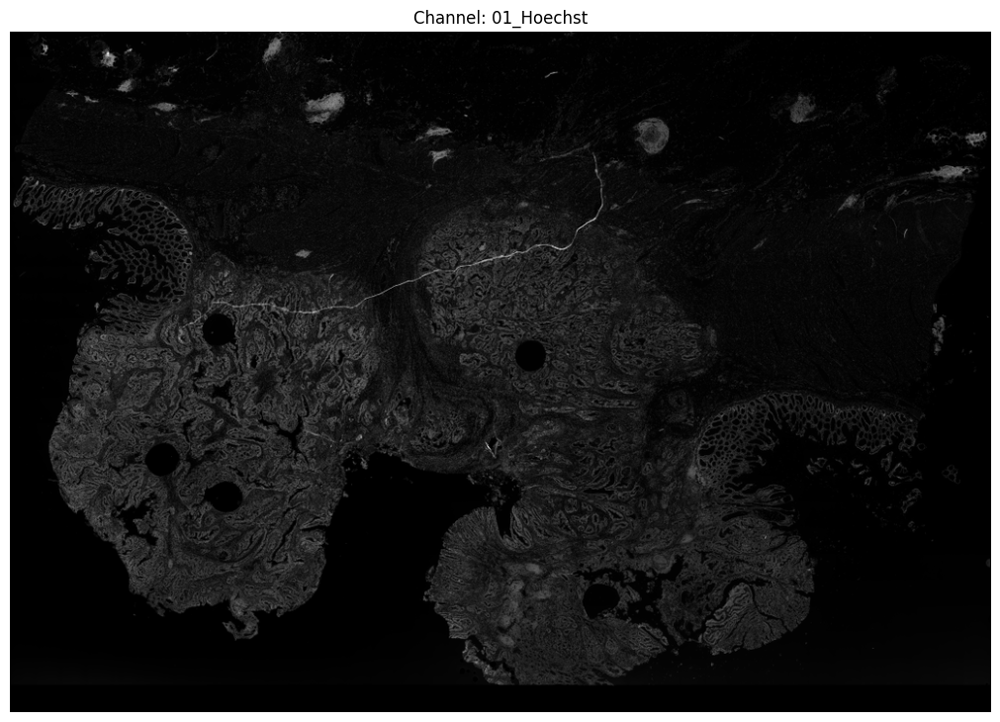

In [8]:
hoechst = slide.get_single_channel_thumbnail(size=(1024, 1024), key="01_Hoechst", numpy=True)
fig, ax = plt.subplots(1, 1, figsize=(10, 10), layout="constrained")
ax.imshow(hoechst, aspect="equal", cmap="gray")
ax.set_title("Channel: 01_Hoechst")
ax.set_axis_off()
plt.show()

To display all channels, read the multiplex thumbnail once with `get_thumbnail`
and slice it, rather than calling `get_single_channel_thumbnail` per channel
(each call reads every channel).

thumbnail shape: (710, 1023, 19)


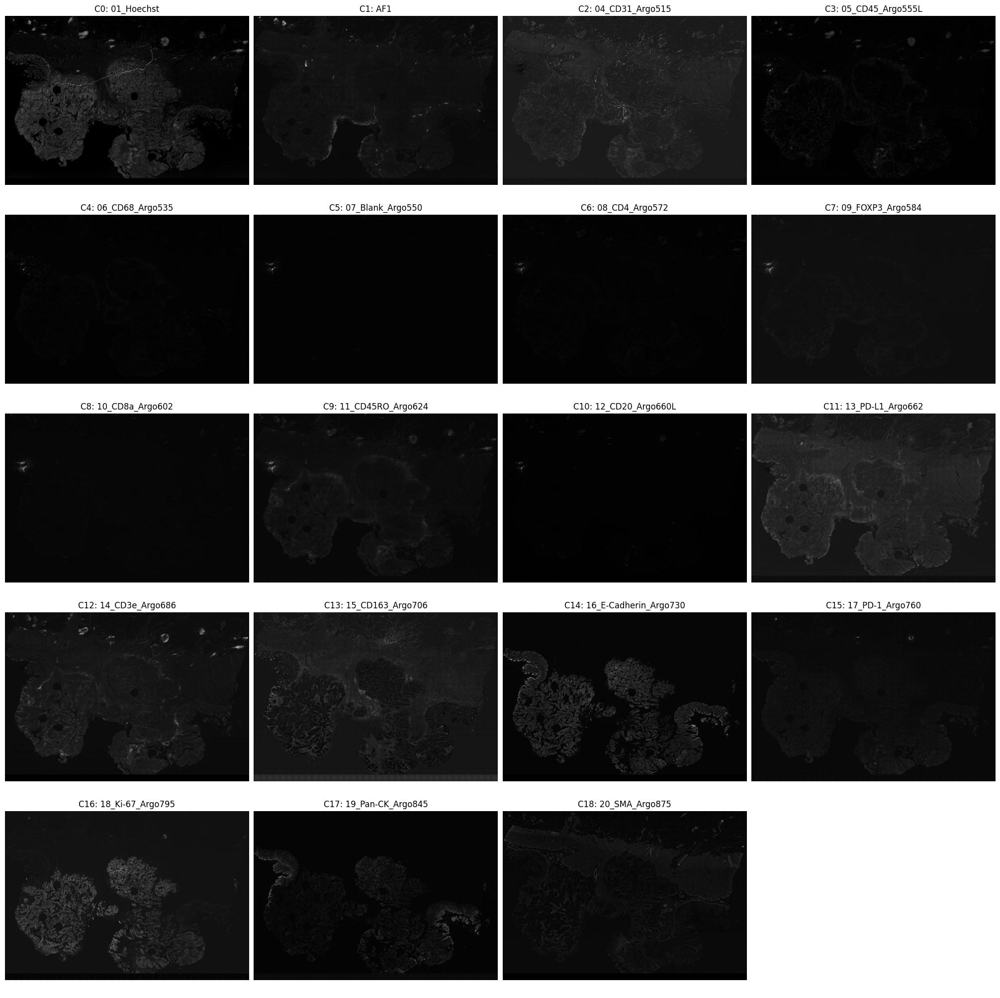

In [9]:
thumbnail = slide.get_thumbnail(size=(1024, 1024), numpy=True)
print(f"thumbnail shape: {thumbnail.shape}")

n_cols = 4
n_rows = int(np.ceil(slide.channel_count / n_cols))
fig, ax = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), layout="constrained")
ax = ax.ravel()
for idx, chnl in enumerate(slide.channel_names):
    ax[idx].imshow(thumbnail[:, :, idx], aspect="equal", cmap="gray")
    ax[idx].set_title(f"C{idx}: {chnl}")
for i in range(len(ax)):
    ax[i].set_axis_off()
plt.show()

## 4. Color blending

Channels are selected by name with `get_channel_index`, so indices always match the titles.

In [ ]:
level = slide.get_best_level_for_downsample(32)[0]
fluo = slide.read_whole(level=level)
print(f"level {level}: {fluo.shape}, {fluo.dtype}")

selected = ["01_Hoechst", "04_CD31_Argo515", "05_CD45_Argo555L", "19_Pan-CK_Argo845", "20_SMA_Argo875"]
chnl_idx = [slide.get_channel_index(name) for name in selected]
colors = ["#FFFFFF", "#FFFD01", "#E833F7", "#00FF00", "#EA3323"]
colors = np.array([ImageColor.getcolor(color, "RGB") for color in colors], dtype=float)
gammas = [0.75, 1.2, 1.2, 1.8, 1.2]

fig, ax = plt.subplots(1, len(selected), figsize=(10 * len(selected), 10))
for i, idx in enumerate(chnl_idx):
    colored = blend_colors(fluo[:, :, idx], colors[i], density_ratio=1e-4, gammas=gammas[i])
    ax[i].imshow(colored, aspect="equal")
    ax[i].set_title(f"C{idx}: {slide.channel_names[idx]}")
    ax[i].axis("off")
plt.show()

NameError: name 'slide' is not defined

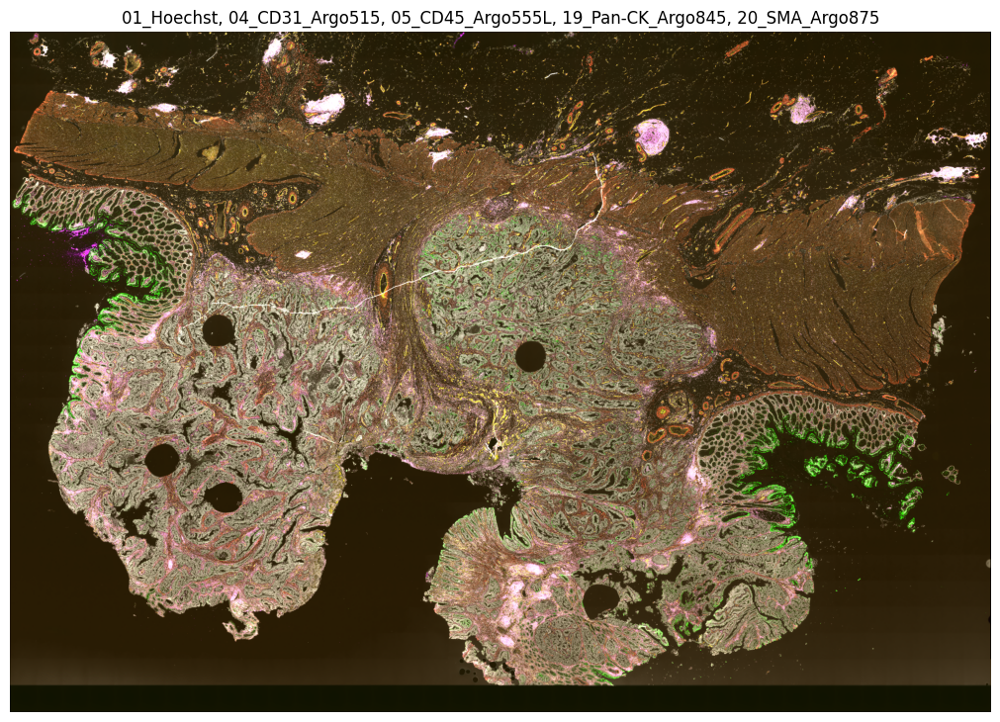

In [11]:
blended_img = blend_colors(
    fluo[:, :, chnl_idx], colors, scale_by="hist", density_ratio=1e-4, gammas=gammas
)
fig, ax = plt.subplots(1, 1, figsize=(10, 10), layout="constrained")
ax.imshow(blended_img, aspect="equal")
ax.set_title(", ".join(selected))
ax.set_axis_off()
plt.show()

The same blend with the channel colors stored in the OME-XML.

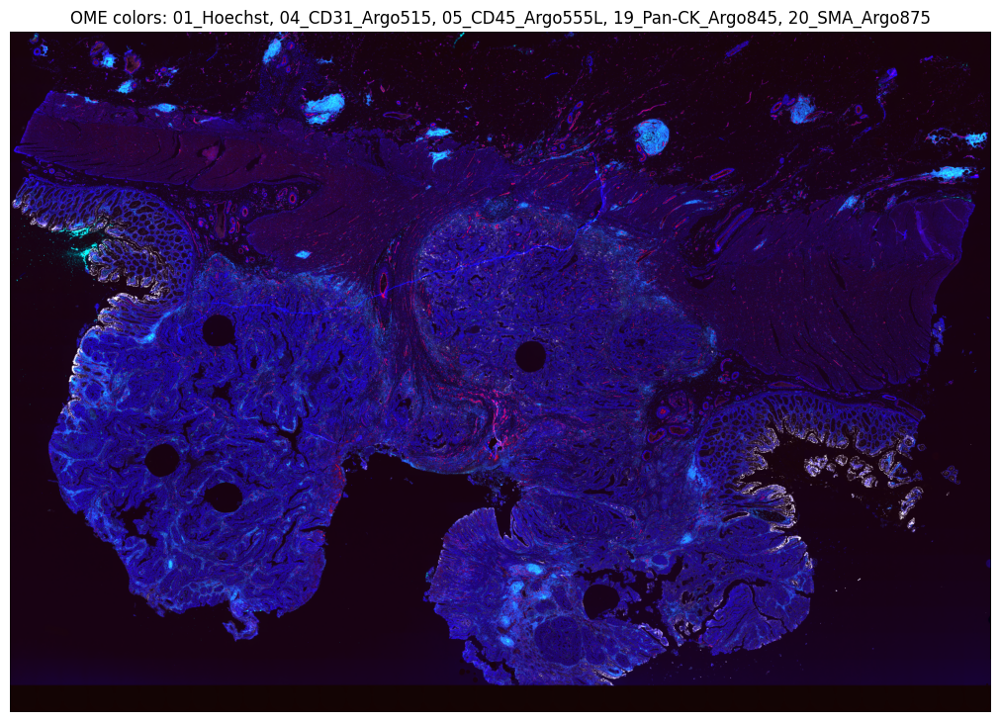

In [12]:
blended_ome = blend_colors(
    fluo[:, :, chnl_idx], slide.channel_colors[chnl_idx], density_ratio=1e-4, gammas=gammas
)
fig, ax = plt.subplots(1, 1, figsize=(10, 10), layout="constrained")
ax.imshow(blended_ome, aspect="equal")
ax.set_title(f"OME colors: {', '.join(selected)}")
ax.set_axis_off()
plt.show()

## 5. Read a region

`location` is always given in level 0 `(x, y)` coordinates, whatever the `level`.
Here it is placed at the center of the tissue, detected on the Hoechst thumbnail.

tissue center (level 0): (32698, 27355)


level 0: location (32186, 26843), shape (1024, 1024, 19)


level 2: location (30650, 25307), shape (1024, 1024, 19)


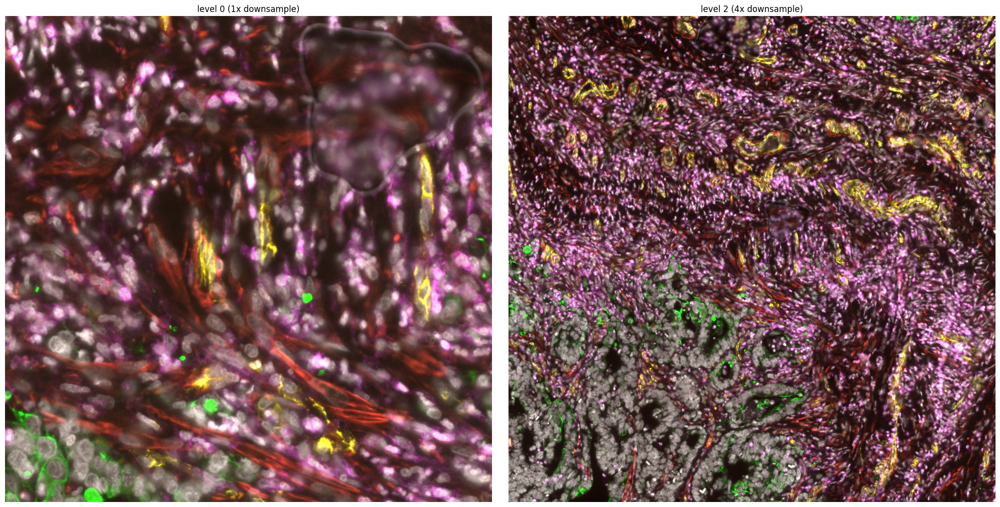

In [13]:
hoechst = fluo[:, :, slide.get_channel_index("01_Hoechst")]
ys, xs = np.nonzero(hoechst > hoechst.mean())
downsample = slide.level_downsamples[level]
center = (int(np.median(xs) * downsample), int(np.median(ys) * downsample))
print(f"tissue center (level 0): {center}")

region_size = (1024, 1024)
regions = {}
for region_level in [0, 2]:
    # shift the location so that the region is centered on `center`
    half = [s * slide.level_downsamples[region_level] / 2 for s in region_size]
    location = (int(center[0] - half[0]), int(center[1] - half[1]))
    regions[region_level] = slide.read_region(location, level=region_level, size=region_size)
    print(f"level {region_level}: location {location}, shape {regions[region_level].shape}")

fig, ax = plt.subplots(1, len(regions), figsize=(10 * len(regions), 10), layout="constrained")
for i, (region_level, region) in enumerate(regions.items()):
    ax[i].imshow(blend_colors(region[:, :, chnl_idx], colors, gammas=gammas), aspect="equal")
    ax[i].set_title(f"level {region_level} ({slide.level_downsamples[region_level]:.0f}x downsample)")
    ax[i].set_axis_off()
plt.show()

A region crossing the image border is cropped (with a warning).

In [14]:
width_0, height_0 = slide.dimensions
border_region = slide.read_region((width_0 - 300, height_0 - 200), level=0, size=(1024, 1024))
print(f"border region shape: {border_region.shape}")

region is out of image bounds 71344 x 49495, size was cropped


border region shape: (200, 300, 19)


With `numpy=False`, 1, 3 or 4 channel arrays are returned as PIL images.

<class 'PIL.Image.Image'> (512, 355) L


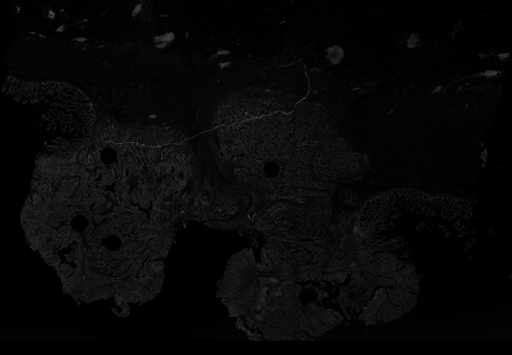

In [15]:
pil_channel = slide.get_single_channel_thumbnail(size=(512, 512), key="01_Hoechst")
print(type(pil_channel), pil_channel.size, pil_channel.mode)
pil_channel

## 6. Invalid inputs

The reader warns and falls back to the lowest resolution for a level that does not exist.

In [16]:
lowest = slide.read_whole(level=99)
print(f"level 99 -> shape {lowest.shape}, level {slide.level_count - 1} dims {slide.level_dimensions[-1]}")

level 99 does not exist, set to lowest resolution level 7


level 99 -> shape (387, 558, 19), level 7 dims (558, 387)


The other invalid inputs raise explicit errors.

In [17]:
invalid_calls = {
    "multiplex thumbnail as PIL": lambda: slide.get_thumbnail(),
    "thumbnail without channel": lambda: slide.get_single_channel_thumbnail(),
    "unknown channel name": lambda: slide.get_channel_index("CD99"),
    "region outside the image": lambda: slide.read_region((width_0 + 10, 0), level=0, size=(64, 64)),
    "negative level": lambda: slide.read_whole(level=-1),
    "non OME-TIFF file": lambda: get_slide_reader("slide.svs"),
}
for description, call in invalid_calls.items():
    try:
        call()
        print(f"{description}: no error")
    except Exception as error:
        print(f"{description}: {type(error).__name__}: {error}")

multiplex thumbnail as PIL: ValueError: Cannot convert an image with 19 channels to PIL, expected 1, 3 or 4. Use `cosmix.bioformats.draw.blend_colors` for multiplex images.
thumbnail without channel: ValueError: need to provide a channel `key` or `idx`
unknown channel name: KeyError: "`key`='CD99' is not a channel name, expected one of ['01_Hoechst', 'AF1', '04_CD31_Argo515', '05_CD45_Argo555L', '06_CD68_Argo535', '07_Blank_Argo550', '08_CD4_Argo572', '09_FOXP3_Argo584', '10_CD8a_Argo602', '11_CD45RO_Argo624', '12_CD20_Argo660L', '13_PD-L1_Argo662', '14_CD3e_Argo686', '15_CD163_Argo706', '16_E-Cadherin_Argo730', '17_PD-1_Argo760', '18_Ki-67_Argo795', '19_Pan-CK_Argo845', '20_SMA_Argo875']"
region outside the image: ValueError: `location`=(71354, 0) is outside the image at level 0 (71344 x 49495)
negative level: ValueError: `level` must be >= 0, got -1
non OME-TIFF file: ValueError: `img_path`=slide.svs is not supported, expected an OME-TIFF (`.ome.tif` or `.ome.tiff`).
